# Lake Michigan–Huron level forecasting: main

This notebook runs the analysis: the ideas behind the models, the backtest and the figures, one idea at a time. Each section gives the intuition first, then the code.

Nothing is defined here. Every function and class lives in `function_declaration.ipynb`; the next cell loads them. Run `data_processing.ipynb` first, then run the cells here top to bottom (the tuning and the backtest in section 6 take about 17 minutes, the whole notebook about 25).

In [1]:
%run ./function_declaration.ipynb
from IPython.display import Image, display

## 0. Load the monthly table

The raw files are turned into one table, one row per month, in `data_processing.ipynb`. That notebook writes `data/processed/monthly.csv`; here we only read it.

In [2]:
df = load_monthly()
df.tail()

,level_m,precip_mm,evap_mm,runoff_mm,frac_gauged_mic,frac_gauged_hur,nbs_mm,dlevel_mm,snow_mic,rain_mic,pdd_mic,snow_hur,rain_hur,pdd_hur
month,,,,,,,,,,,,,,
2023-08,176.70,87.0086,62.9977,24.5482,0.974,0.828,48.5591,0.0,0.00,85.68,613.535,0.00,97.55,571.360
2023-09,176.64,47.3090,44.0508,18.0159,0.974,0.828,21.2741,-60.0,0.00,50.38,525.520,0.00,33.33,500.005
2023-10,176.56,112.1858,79.4914,26.1452,0.979,0.828,58.8396,-80.0,0.00,116.68,346.410,0.00,98.22,336.110
2023-11,176.51,52.1705,100.1989,28.9006,0.960,0.828,-19.1278,-50.0,10.05,30.80,123.255,7.80,40.35,96.525
2023-12,176.44,47.4808,61.2137,35.6816,0.941,0.828,21.9487,-70.0,0.98,48.32,80.330,2.88,46.72,75.370


## 1. The lake as a bathtub

**Intuition.** The lake level goes up when more water comes in than leaves. Water comes in as rain on the lake (P) and river runoff (R); it leaves by evaporation (E) and through the St. Clair River. `nbs_mm` = P − E + R is the *net basin supply*: how many millimetres the lake would rise in a month if nothing flowed out.

Runoff arrives in m³/s, so `runoff_to_depth_mm` spreads that volume over the lake's 117,400 km² to turn it into millimetres. Check one month by hand:

In [3]:
print(f"{1500 * 30 * 86_400 / 117_400e6 * 1000:.1f} mm")  # 1500 m^3/s, a typical runoff, for 30 days over 117,400 km^2

33.1 mm


**Figure 9.** The whole water balance in one picture:

wrote figures/fig9_lake_system.png


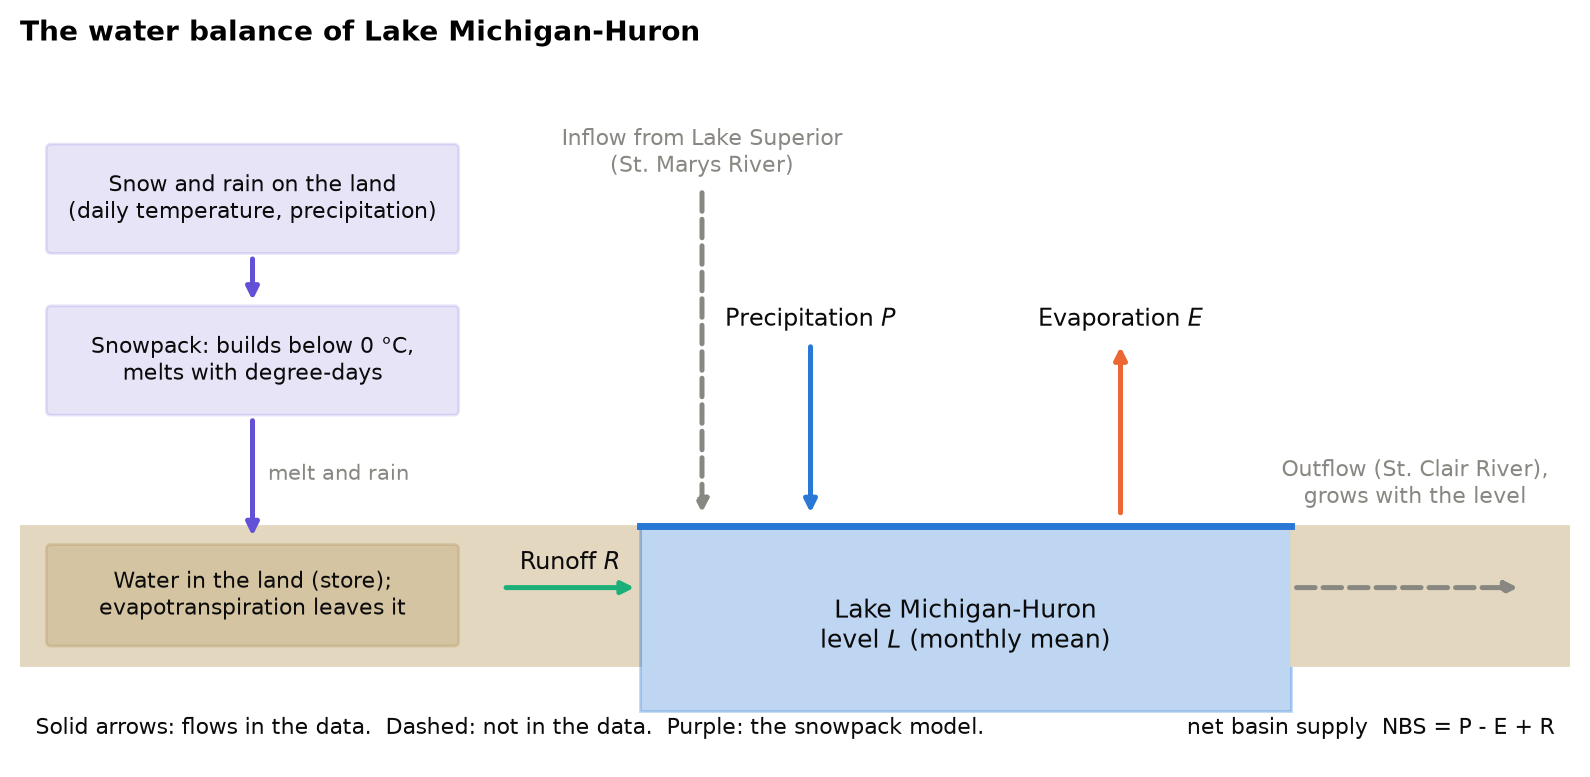

In [4]:
fig9_lake_system()
display(Image(str(FIGURES / "fig9_lake_system.png"), width=800))

## 2. Why predict the *change*, not the level

**Intuition.** The level this month is almost identical to last month's, so a model that just copies the last value looks brilliant if you score the level directly. Predicting the change removes that free ride.

In [5]:
print('correlation of level with last month:       ', round(df.level_m.autocorr(1), 3))
print('correlation of level CHANGE with last month:', round(df.dlevel_mm.autocorr(1), 3))

correlation of level with last month:        0.987
correlation of level CHANGE with last month: 0.703


## 3. Does the bathtub picture hold?

**Intuition.** If the water budget is right, level change should track NBS with a slope near 1. The levels are monthly *averages*, so the change between two averages straddles two months of supply; we average NBS over this month and last month. This is Figure 2 of the report.

wrote figures/fig2_water_balance_check.png
{'r': 0.81, 'slope': 1.07, 'intercept': -68.63}


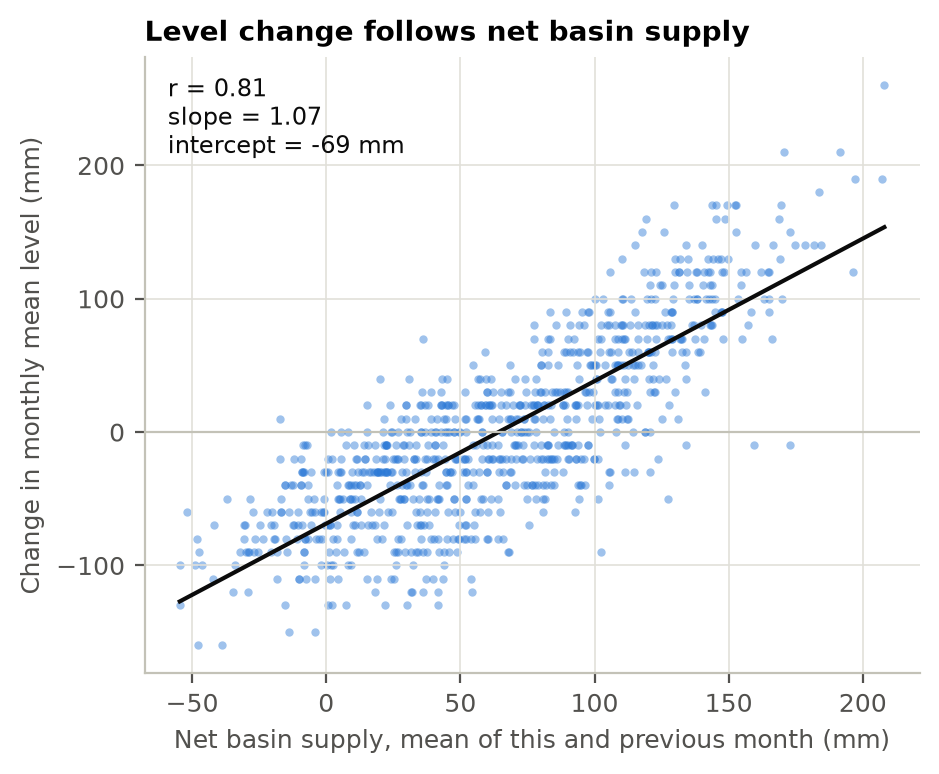

In [6]:
print({k: round(float(v), 2) for k, v in fig2_water_balance(df).items()})
display(Image(str(FIGURES / "fig2_water_balance_check.png"), width=450))

The slope is close to 1. The intercept (about −69 mm/month) is the water that leaves through the rivers on average, which we have no data for.

## 4. The seasonal cycle is a strong baseline

**Intuition.** The lake rises every spring (snowmelt) and falls every autumn (evaporation). A forecast that only knows the calendar already does well, so any model has to beat *this*, not just persistence.

In [7]:
clim = SeasonalClimatology().fit(df)
(clim.mean_change_ / 10).round(1).rename('average level change (cm)').to_frame().T

,1,2,3,4,5,6,7,8,9,10,11,12
average level change (cm),-3.7,-1.8,1.5,8.5,9.8,6.4,3.1,-1.7,-5.1,-6.5,-5.5,-4.3


## 5. The water-balance model

**Intuition.** A regression shaped like the bathtub: level change = supply terms (this month and last) + a monthly constant + a term that lets outflow grow when the lake is high. Coefficients near +1 for P and R and −1 for E would mean a perfect water budget.

In [8]:
wb = WaterBalance().fit(df)
c = wb.coefficients()
print('P  (lag0 + lag1):', round(c['precip_mm_lag0'] + c['precip_mm_lag1'], 2))
print('E  (lag0 + lag1):', round(c['evap_mm_lag0'] + c['evap_mm_lag1'], 2))
print('R  (lag0 + lag1):', round(c['runoff_mm_lag0'] + c['runoff_mm_lag1'], 2))
print('level (mm per m):', round(c['level_m'], 1))

P  (lag0 + lag1): 0.88
E  (lag0 + lag1): -0.81
R  (lag0 + lag1): 1.83
level (mm per m): -23.0


P and E are near ±1 and the level term is negative, as expected. Runoff is well above 1, which means it is standing in for something unmeasured (see the report's limitations).

**To forecast**, we do not know next month's weather. The model fills it in with the seasonal average plus a fading share of the latest anomaly. How fast does an anomaly fade?

In [9]:
dict(zip(['precip', 'evap', 'runoff'], wb.phi_.round(2).tolist()))

{'precip': 0.02, 'evap': 0.26, 'runoff': 0.45}

Precipitation anomalies do not carry over at all (≈0); runoff carries over about half. This is why skill fades quickly with horizon.

## 5b. The lake model

**Intuition.** The same bathtub, but simulated instead of fitted as a regression: the lake fills
with P − E + R and the channel flow, and drains faster when it is high, like water over a weir
(outflow grows with the depth to the power 1.5). It is stepped ten times a month and averaged,
because the observed levels are monthly means. The scaling factors for P, E and R show how far
the budget is from closing with the raw estimates (1 would be a closed budget).

In [10]:
lake = LakeModel().fit(df)
dict(zip(["mP", "mE", "mR", "c (mm/month)", "d (m)"], lake.p_[[0, 1, 2, 15, 16]].round(2).tolist()))

{'mP': 1.0, 'mE': 0.86, 'mR': 1.73, 'c (mm/month)': 24.72, 'd (m)': 1.5}

P and E are close to 1. Runoff is again well above 1, as in the water-balance regression, so the missing channel flows are still being absorbed by the runoff term. `d` sits at its lower bound of 1.5 m: the data ask for an outflow that bends more sharply with level than the bound allows.

## 5c. The snowpack

**Intuition.** Snow that falls on the land in winter does not reach the lake until it melts in spring, so a big snowpack at the end of winter means extra runoff in the months ahead. The AR(1) runoff forecast cannot see the snowpack; this model simulates it from the daily over-land temperature and precipitation. Fitted on the full record:

In [11]:
snow = SnowRunoff().fit(df)
dict(zip(["ddf", "k", "e", "a_mic", "a_hur"], snow.p_.round(3).tolist()))

{'ddf': 2.594, 'k': 0.343, 'e': 0.131, 'a_mic': 0.551, 'a_hur': 0.453}

**Figure 8.** Does the simulated snowpack really turn into runoff? Its seasonal cycle, and the end-of-March snowpack of every year against the runoff of the following April to June:

wrote figures/fig8_snowpack.png
correlation of the end-of-March snowpack with April-June runoff: 0.31


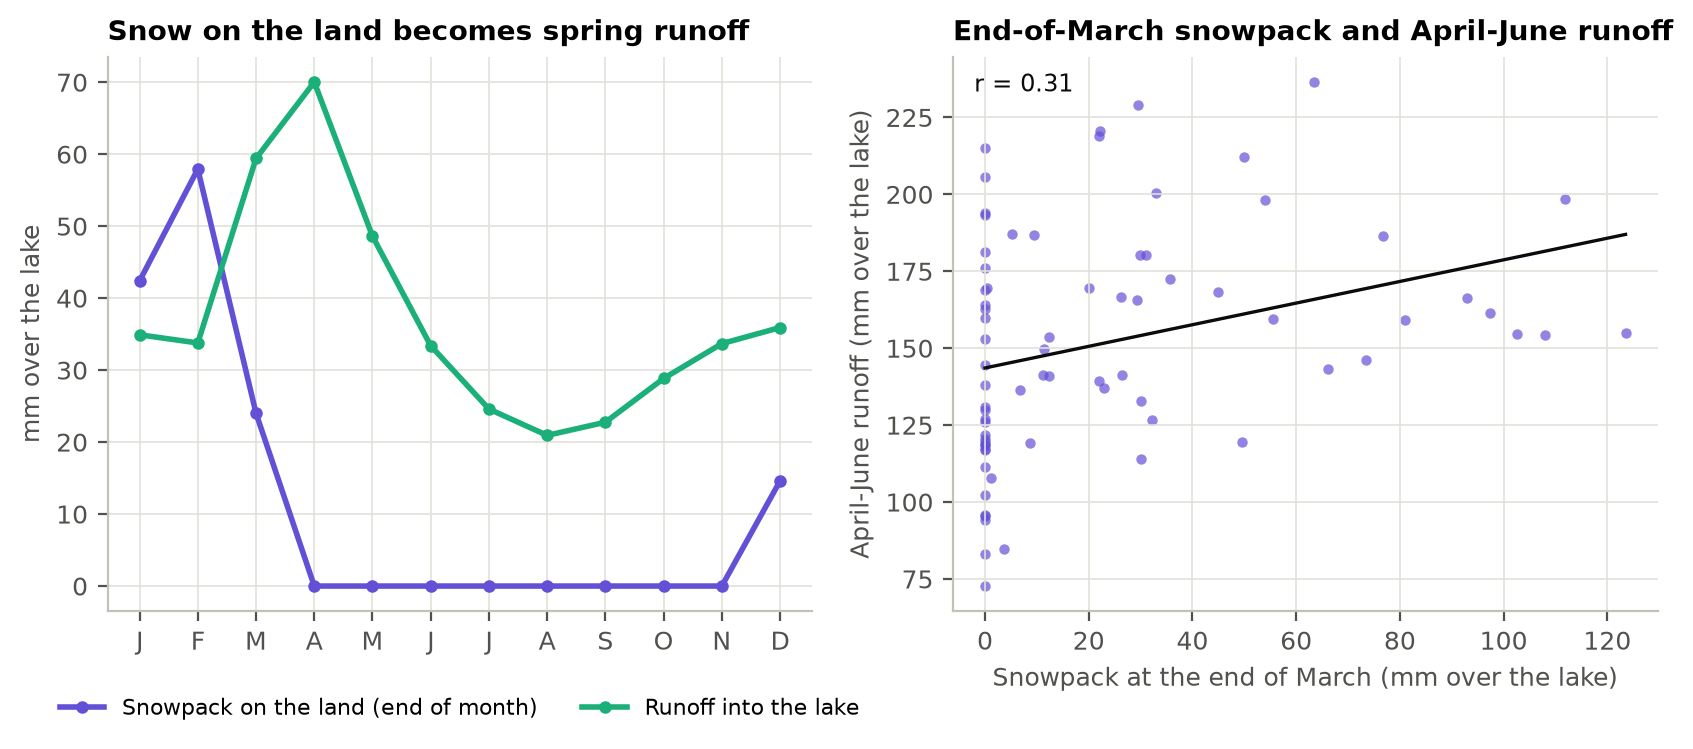

In [12]:
print("correlation of the end-of-March snowpack with April-June runoff:", round(float(fig8_snowpack(snow, df)), 2))
display(Image(str(FIGURES / "fig8_snowpack.png"), width=800))

## 6. Rolling-origin backtest

**Intuition.** To test honestly, a model must never see the year it is tested on. For each year from 1980 on, we train on everything before it, forecast that year, then step forward. `backtest` does this for every model and every forecast is saved to `data/processed/predictions.csv`.

The backtest cell takes about 12 minutes.

wrote figures/fig10_backtest.png


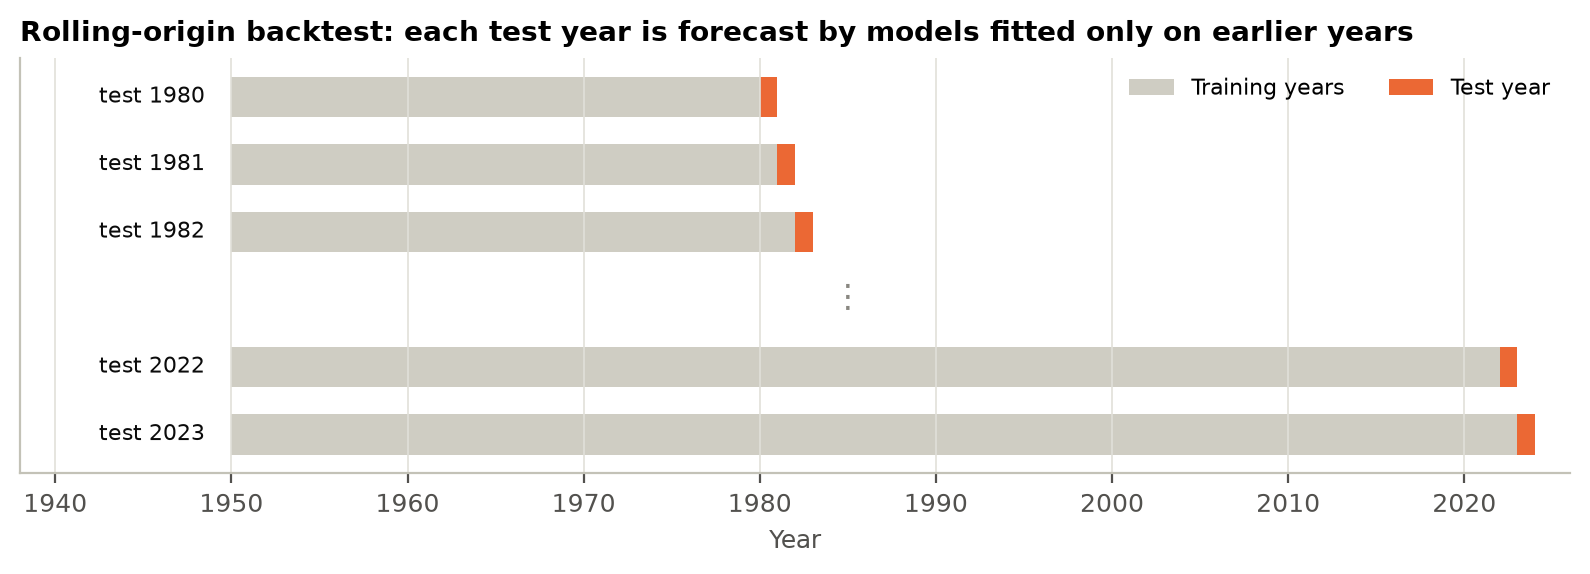

In [13]:
fig10_backtest()
display(Image(str(FIGURES / "fig10_backtest.png"), width=800))

**Tuning gradient boosting first.** Gradient boosting uses settings fixed in advance. To give it a fair chance, 36 combinations of the number of trees, the learning rate and the tree depth are scored in the same kind of backtest on 1950–1979 alone (test years 1965–1979). The best one, by RMSE averaged over the six horizons, is `GB_TUNED`, which the backtest below runs as "Gradient boosting, tuned". No year from 1980 on is used. This cell takes about 4 minutes.

In [14]:
tuning = tune_gb(df)
tuning.to_csv(PROCESSED / "gb_tuning.csv", float_format="%.3f")
score = tuning.mean(axis=1)
assert score.idxmin() == str(GB_TUNED)
print("best on 1965-1979:", GB_TUNED, "| the fixed settings rank", int(score.rank()[str({k: GradientBoosting.params[k] for k in GB_TUNED})]), "of", len(score))
tuning.assign(mean=score).sort_values("mean").head().round(2)

best on 1965-1979: {'n_estimators': 1000, 'learning_rate': 0.01, 'max_depth': 1} | the fixed settings rank 16 of 36


horizon,1,2,3,4,5,6,mean
model,,,,,,,
"{'n_estimators': 1000, 'learning_rate': 0.01, 'max_depth': 1}",3.48,6.75,9.12,11.24,13.60,15.86,10.01
"{'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 1}",3.48,6.74,9.10,11.24,13.61,15.95,10.02
"{'n_estimators': 300, 'learning_rate': 0.01, 'max_depth': 3}",3.47,6.65,9.10,11.53,13.61,15.89,10.04
"{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 1}",3.45,6.71,9.08,11.16,13.74,16.26,10.07
"{'n_estimators': 300, 'learning_rate': 0.01, 'max_depth': 2}",3.53,6.77,9.26,11.54,13.62,15.87,10.10


In [15]:
preds = backtest(df)
preds.to_csv(PROCESSED / "predictions.csv", index=False, float_format="%.4f")

table = rmse_table(preds)
table.to_csv(PROCESSED / "rmse_by_horizon.csv", float_format="%.3f")
years = preds["target"].dt.year
print(f"\nRMSE (cm) by horizon, test years {years.min()}-{years.max()}, "
      f"{preds['target'].nunique()} target months")
table.round(2)


RMSE (cm) by horizon, test years 1980-2023, 528 target months


horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Water balance + snowpack,3.22,6.26,8.67,10.79,12.66,14.25
Lake model,3.26,6.38,8.88,11.12,13.08,14.78
Lake model + snowpack,3.25,6.30,8.73,10.89,12.79,14.40
Gradient boosting,3.32,6.51,9.12,11.40,13.48,15.39
Gradient boosting + snowpack,3.31,6.49,9.02,11.30,13.55,15.14
"Gradient boosting, tuned",3.42,6.45,8.93,11.51,14.04,16.09


Reload the saved forecasts, so everything below uses exactly what is on disk:

In [16]:
preds = pd.read_csv(PROCESSED / "predictions.csv")
for col in ("target", "origin"):
    preds[col] = pd.PeriodIndex(preds[col], freq="M")
rmse_table(preds).round(2)

horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Water balance + snowpack,3.22,6.26,8.67,10.79,12.66,14.25
Lake model,3.26,6.38,8.88,11.12,13.08,14.78
Lake model + snowpack,3.25,6.30,8.73,10.89,12.79,14.40
Gradient boosting,3.32,6.51,9.12,11.40,13.48,15.39
Gradient boosting + snowpack,3.31,6.49,9.02,11.30,13.55,15.14
"Gradient boosting, tuned",3.42,6.45,8.93,11.51,14.04,16.09


**Reading the table (RMSE in cm, lower is better).** Everything beats persistence. The linear regression on the gradient-boosting features is best at one and four to six months, and water balance + snowpack at two and three; gradient boosting, the lake model and the physics-guided CNN are slightly worse than the plain water balance, and tuned gradient boosting is worse still at five and six months. Is that gap real? Resample whole test years and look at the 95% interval of the difference:

In [17]:
bootstrap_rmse_diff(preds, 'Gradient boosting', 'Water balance').round(2)

,diff_cm,ci_low,ci_high
horizon,,,
1,0.10,-0.02,0.23
2,0.18,-0.07,0.44
3,0.30,-0.09,0.68
4,0.38,-0.15,0.92
5,0.52,-0.16,1.21
6,0.73,-0.14,1.63


Every interval includes zero: gradient boosting is not *significantly* worse, but there is no sign it is better.

The row `WB, perfect forcing` is not a forecast. It uses the weather that actually happened, and shows how much error is simply not knowing the future.

The same comparison for the other pairs of models:

In [18]:
for a, b in [("Water balance + snowpack", "Water balance"),
             ("Gradient boosting + snowpack", "Gradient boosting"),
             ("Lake model + snowpack", "Lake model"),
             ("Lake model", "Water balance"),
             ("Physics-guided CNN", "Lake model"),
             ("Hybrid (WB + GB residual)", "Water balance"),
             ("Gradient boosting, tuned", "Gradient boosting"),
             ("Gradient boosting, tuned", "Water balance"),
             ("Linear regression (same features)", "Gradient boosting"),
             ("Linear regression (same features)", "Water balance"),
             ("Linear regression (same features)", "Water balance + snowpack"),
             ("Gradient boosting", "Seasonal climatology"),
             ("Water balance", "Seasonal climatology")]:
    print(f"\nRMSE({a}) - RMSE({b}), cm; negative = first is better")
    print(bootstrap_rmse_diff(preds, a, b).round(2).to_string())


RMSE(Water balance + snowpack) - RMSE(Water balance), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.00   -0.04     0.04
2          -0.08   -0.20     0.08
3          -0.15   -0.35     0.07
4          -0.23   -0.51     0.09
5          -0.31   -0.62     0.04
6          -0.41   -0.76    -0.01

RMSE(Gradient boosting + snowpack) - RMSE(Gradient boosting), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.01   -0.04     0.01
2          -0.02   -0.13     0.09
3          -0.09   -0.26     0.07
4          -0.10   -0.34     0.18
5           0.07   -0.29     0.45
6          -0.25   -0.69     0.25

RMSE(Lake model + snowpack) - RMSE(Lake model), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.01   -0.04     0.02
2          -0.08   -0.19     0.05
3          -0.15   -0.32     0.05
4          -0.22   -0.47     0.07
5          -0.29   -0.58     0.03
6          -0.38   -0.72    -0.01

RMSE(Lake model) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1           0.05    0.02     0.07
2           0.05    0.00     0.09
3           0.07    0.00     0.13
4           0.09    0.01     0.17
5           0.11    0.01     0.21
6           0.12   -0.00     0.24

RMSE(Physics-guided CNN) - RMSE(Lake model), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.00   -0.01     0.01
2          -0.01   -0.03     0.01
3          -0.01   -0.06     0.02
4          -0.02   -0.11     0.06
5          -0.03   -0.15     0.10
6          -0.02   -0.19     0.14

RMSE(Hybrid (WB + GB residual)) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1           0.05   -0.04     0.13
2           0.01   -0.17     0.19
3           0.13   -0.18     0.45
4           0.15   -0.29     0.62
5           0.03   -0.53     0.62
6          -0.08   -0.78     0.65

RMSE(Gradient boosting, tuned) - RMSE(Gradient boosting), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1           0.10   -0.03     0.22
2          -0.07   -0.24     0.11
3          -0.18   -0.43     0.10
4           0.10   -0.28     0.47
5           0.56    0.12     1.01
6           0.70    0.08     1.27

RMSE(Gradient boosting, tuned) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1           0.20    0.08     0.32
2           0.12   -0.14     0.37
3           0.12   -0.23     0.43
4           0.48   -0.04     0.99
5           1.08    0.42     1.74
6           1.43    0.69     2.21

RMSE(Linear regression (same features)) - RMSE(Gradient boosting), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.15   -0.27    -0.03
2          -0.14   -0.38     0.10
3          -0.37   -0.76     0.06
4          -0.67   -1.11    -0.22
5          -0.99   -1.57    -0.47
6          -1.33   -2.05    -0.58

RMSE(Linear regression (same features)) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.05   -0.15     0.08
2           0.04   -0.20     0.29
3          -0.07   -0.42     0.31
4          -0.29   -0.82     0.25
5          -0.47   -1.12     0.17
6          -0.60   -1.41     0.18

RMSE(Linear regression (same features)) - RMSE(Water balance + snowpack), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.04   -0.15     0.08
2           0.11   -0.12     0.35
3           0.08   -0.26     0.42
4          -0.06   -0.57     0.43
5          -0.17   -0.82     0.48
6          -0.19   -1.00     0.55

RMSE(Gradient boosting) - RMSE(Seasonal climatology), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.81   -1.05    -0.58
2          -0.55   -0.97    -0.13
3          -0.37   -0.95     0.21
4          -0.22   -0.96     0.48
5          -0.04   -0.90     0.82
6           0.12   -1.01     1.20

RMSE(Water balance) - RMSE(Seasonal climatology), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.92   -1.12    -0.70
2          -0.73   -1.17    -0.28
3          -0.67   -1.26    -0.08
4          -0.60   -1.41     0.20
5          -0.56   -1.59     0.48
6          -0.61   -1.99     0.65


Which models are clearly better than the seasonal climatology, and at which horizons (the whole 95% interval below zero)?

In [19]:
{m: [h for h, r in bootstrap_rmse_diff(preds, m, "Seasonal climatology").iterrows() if r["ci_high"] < 0] for m in rmse_table(preds).index[2:12]}

{'Water balance': [1, 2, 3],
 'Water balance + snowpack': [1, 2, 3],
 'Lake model': [1, 2],
 'Lake model + snowpack': [1, 2, 3],
 'Gradient boosting': [1, 2],
 'Gradient boosting + snowpack': [1, 2],
 'Gradient boosting, tuned': [1, 2, 3],
 'Linear regression (same features)': [1, 2, 3, 4, 5, 6],
 'Hybrid (WB + GB residual)': [1, 2],
 'Physics-guided CNN': [1, 2]}

The physics-guided CNN starts as the lake model and only moves away from it in years where early stopping found a better epoch on held-out training months:

In [20]:
t = preds.pivot_table(index="target", columns="model", values="predicted_m")
print("CNN differs from the lake model in:", sorted(set(t.index[(t["Physics-guided CNN"] - t["Lake model"]).abs() > 1e-9].year)))

CNN differs from the lake model in: [2001, 2002, 2003, 2004, 2007]


## 6b. Forecast ranges

**Intuition.** A single number hides how uncertain a forecast is. The water-balance model is run once for every past year, with that year's weather anomalies added to the AR(1) weather forecast, and the spread of the results gives a range. Only years before the test year are used. A good 80% range should hold the observed level about 80% of the time. The weather is not the only source of error, so the errors the model makes on the training years even with the observed weather are added too; the weather-only ranges are kept for comparison.

wrote figures/fig7_forecast_ranges.png


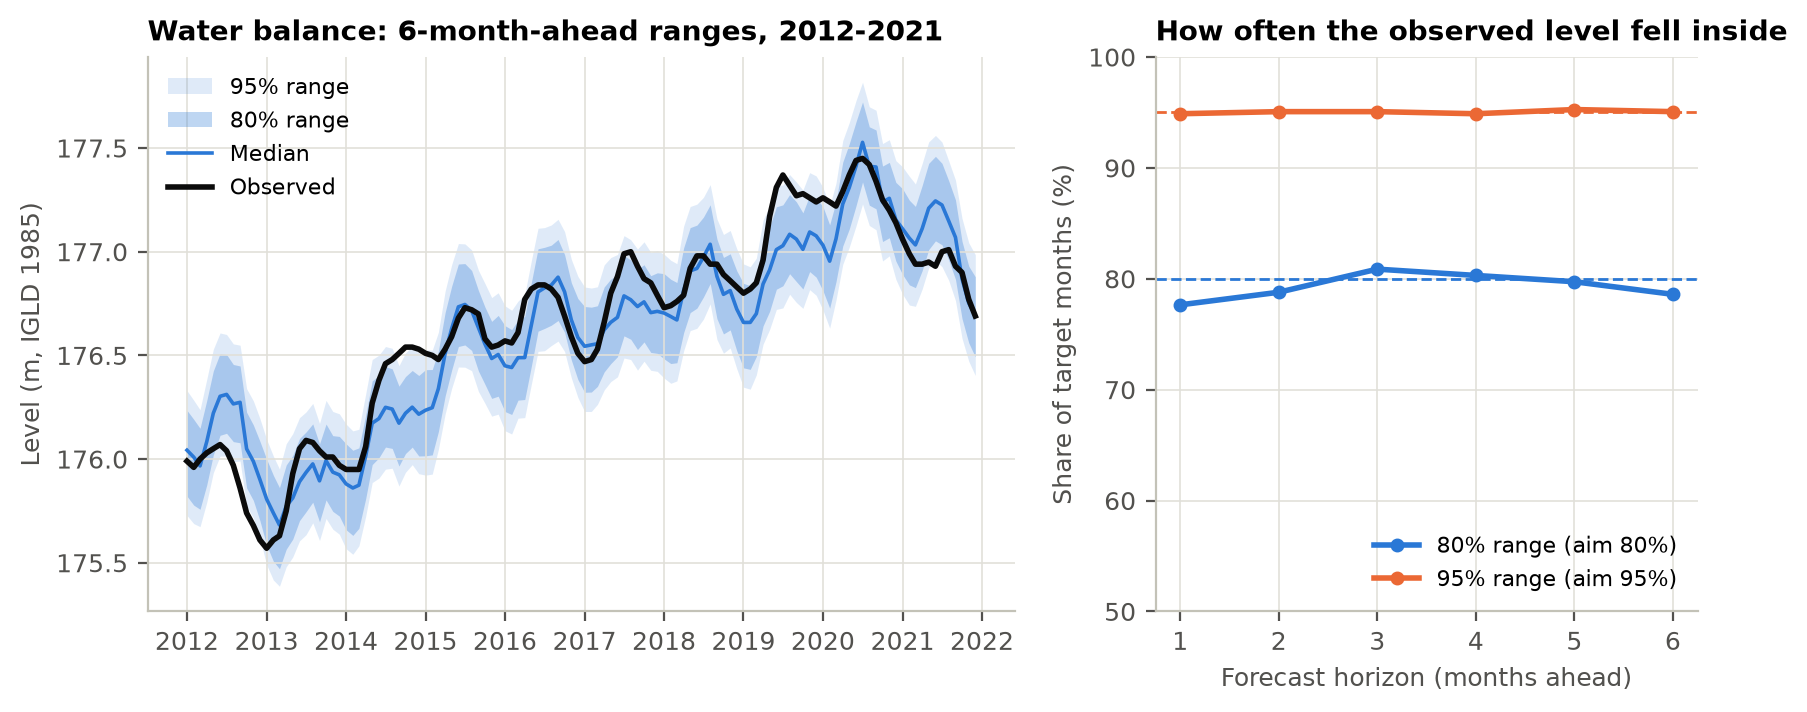

median width of the 80% range (cm): {1: 8.1, 2: 16.3, 3: 23.2, 4: 29.1, 5: 34.5, 6: 39.1}
weather only, % inside the 80% and 95% ranges: {1: (59.8, 76.1), 2: (69.1, 84.7), 3: (70.8, 86.0), 4: (70.6, 86.4), 5: (70.8, 87.5), 6: (72.7, 85.4)}


,80% range,95% range
horizon,,
1,77.7,94.9
2,78.8,95.1
3,80.9,95.1
4,80.3,94.9
5,79.7,95.3
6,78.6,95.1


In [21]:
ranges = ensemble_backtest(df, model_error=True)  # about two minutes, with the weather-only ranges
weather_only = ensemble_backtest(df)
ranges.to_csv(PROCESSED / "forecast_ranges.csv", index=False, float_format="%.4f")
cover = fig7_ranges(ranges, df)
display(Image(str(FIGURES / "fig7_forecast_ranges.png"), width=800))
print("median width of the 80% range (cm):", (100 * (ranges["q0.9"] - ranges["q0.1"])).groupby(ranges["horizon"]).median().round(1).to_dict())
print("weather only, % inside the 80% and 95% ranges:", {h: (round(float(100 * g["observed_m"].between(g["q0.1"], g["q0.9"]).mean()), 1), round(float(100 * g["observed_m"].between(g["q0.025"], g["q0.975"]).mean()), 1)) for h, g in weather_only.groupby("horizon")})
cover.round(1)

**Figure 11.** What one set of forecasts looks like, made at the end of March 2023:

wrote figures/fig11_example_forecast.png


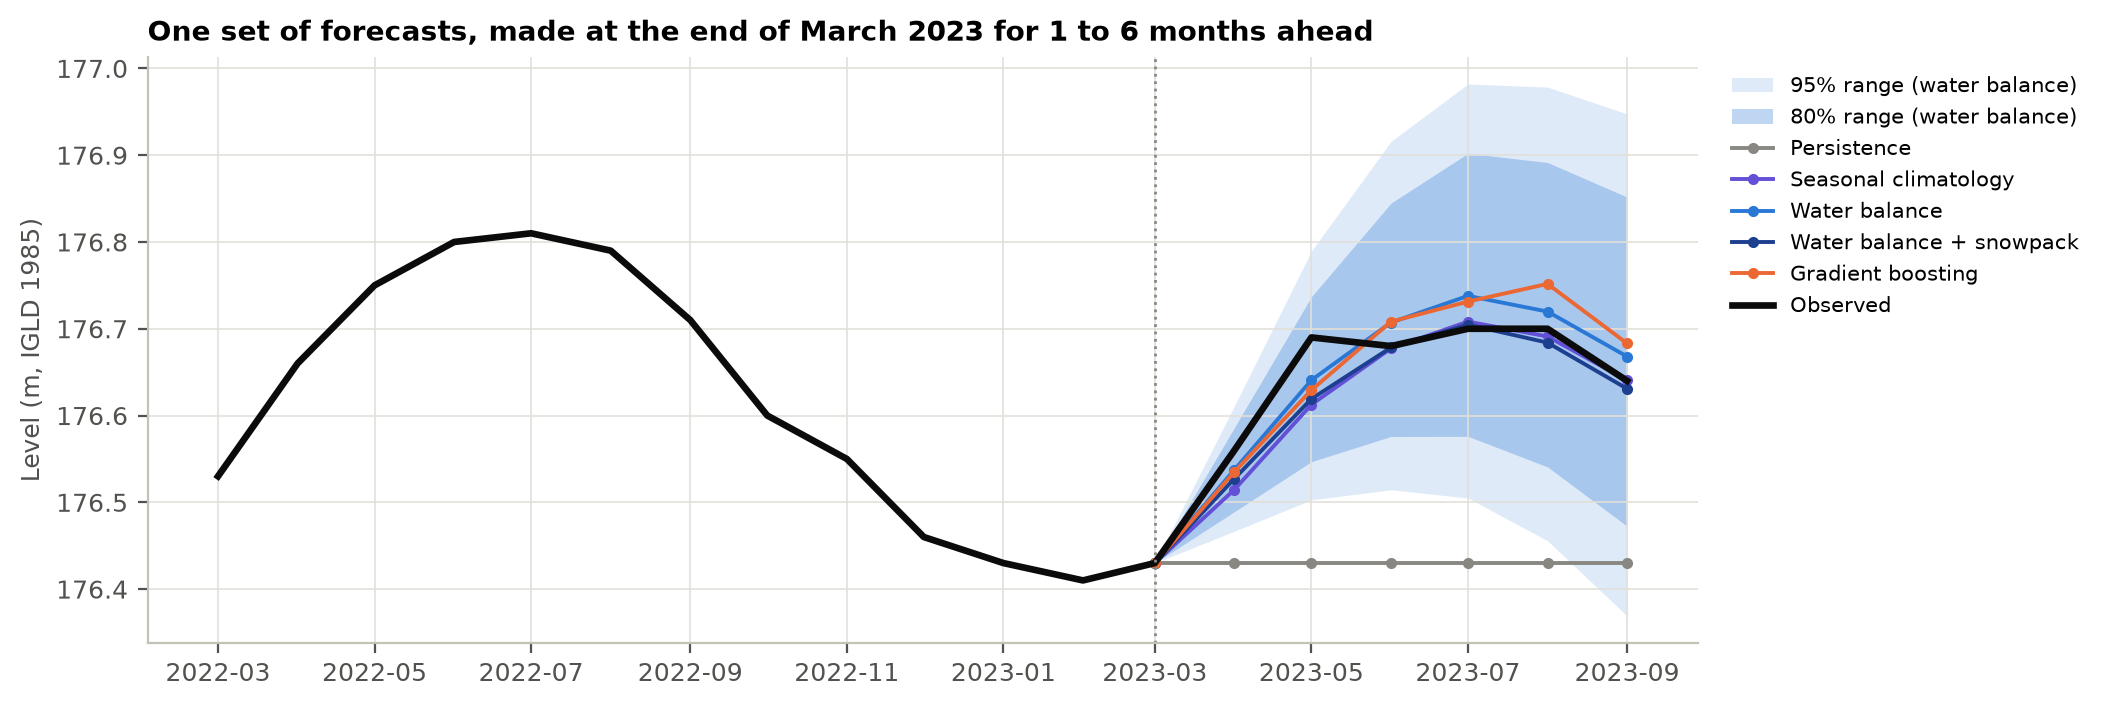

In [22]:
fig11_example(preds, ranges, df)
display(Image(str(FIGURES / "fig11_example_forecast.png"), width=800))

## 6c. Data delays

**Intuition.** The backtest lets every model know P, E and R up to the end of the origin month, but in practice these estimates are published later. How much skill would be lost if they arrived one, two or three months late? The level is measured every day, so it stays known. The missing months are filled in with the AR(1) forecast from the last published month. A delay of 0 repeats the backtest and must give the same numbers. The four runs go in parallel and take about 4 minutes.

In [23]:
delays = pd.concat(Parallel(n_jobs=-1)(delayed(delay_backtest)(df, d) for d in range(4)), keys=range(4), names=["delay"])
delays.to_csv(PROCESSED / "delay_rmse.csv", float_format="%.3f")
print("delay 0 repeats the backtest:", np.allclose(delays.loc[0], rmse_table(preds).loc[delays.loc[0].index], atol=1e-3))
delays.round(2)

delay 0 repeats the backtest: True


horizon                                     1     2     3      4      5      6
delay model                                                                   
0     Water balance                      3.22  6.33  8.82  11.03  12.96  14.66
      Water balance + snowpack           3.22  6.26  8.67  10.79  12.66  14.25
      Gradient boosting                  3.32  6.51  9.12  11.40  13.48  15.39
      Linear regression (same features)  3.17  6.37  8.74  10.74  12.49  14.06
1     Water balance                      4.15  7.08  9.50  11.61  13.45  15.11
      Water balance + snowpack           4.14  7.04  9.43  11.49  13.26  14.87
      Gradient boosting                  3.95  6.95  9.50  11.77  13.78  15.76
      Linear regression (same features)  4.12  7.06  9.41  11.17  12.71  14.23
2     Water balance                      4.19  7.14  9.56  11.67  13.51  15.18
      Water balance + snowpack           4.18  7.12  9.54  11.61  13.43  15.07
      Gradient boosting                  3.94  6.94  9.53  11.73  13.85  15.71
      Linear regression (same features)  4.09  7.04  9.46  11.33  12.96  14.47
3     Water balance                      4.21  7.16  9.58  11.69  13.54  15.22
      Water balance + snowpack           4.21  7.15  9.57  11.68  13.52  15.16
      Gradient boosting                  3.93  6.87  9.51  11.76  13.70  15.31
      Linear regression (same features)  4.10  7.06  9.56  11.54  13.24  14.75

## 7. Figures

Each call writes one report figure to `figures/` and the cell then shows it.

**Figure 1.** The data: the level record, and how each supply term varies through the year.

wrote figures/fig1_data_overview.png


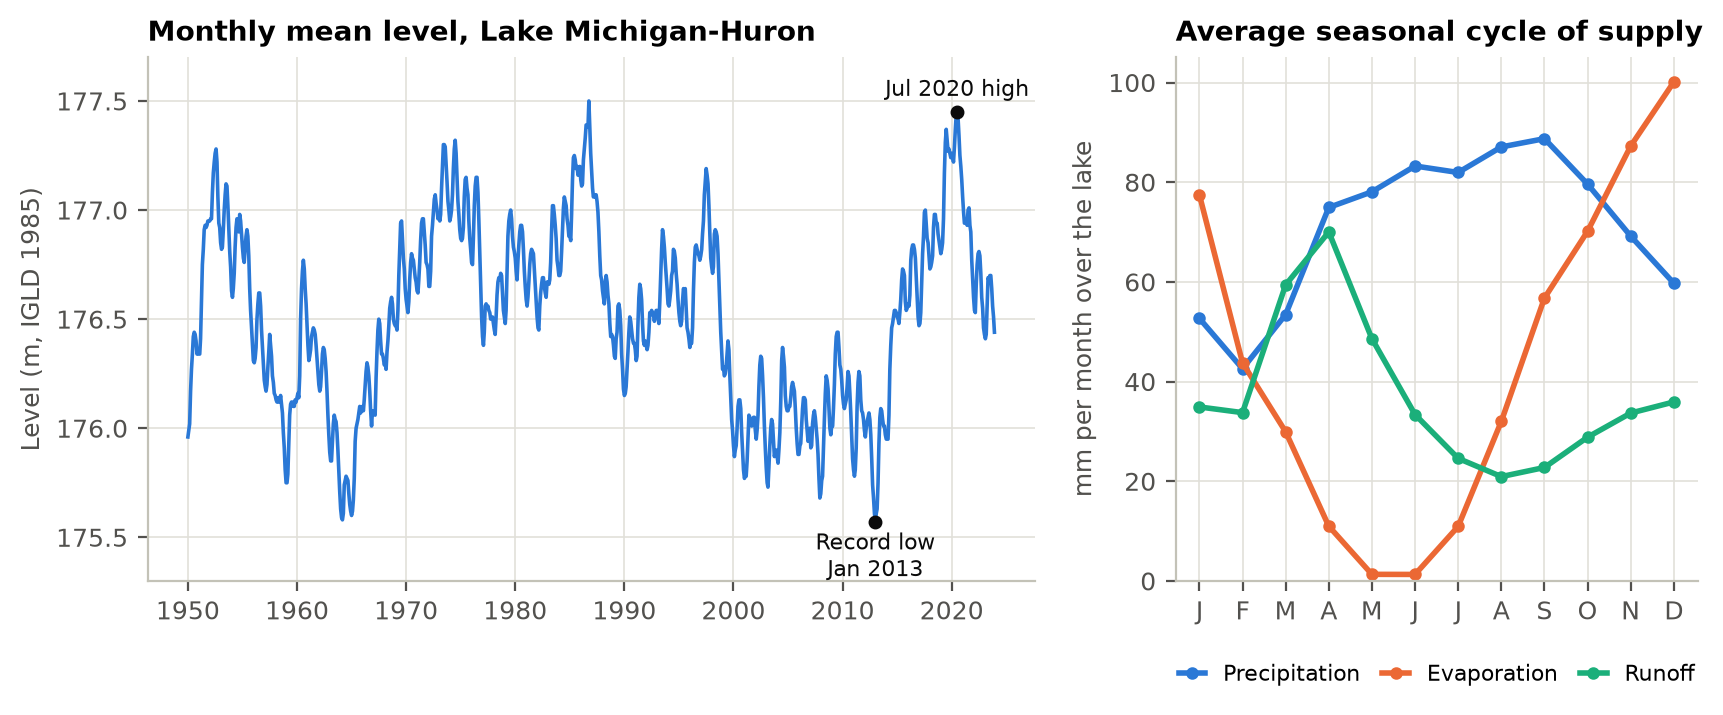

In [24]:
fig1_data(df)
display(Image(str(FIGURES / "fig1_data_overview.png"), width=800))

**Figure 3.** Error by horizon for every model, and how much each improves on the seasonal baseline.

wrote figures/fig3_rmse_by_horizon.png


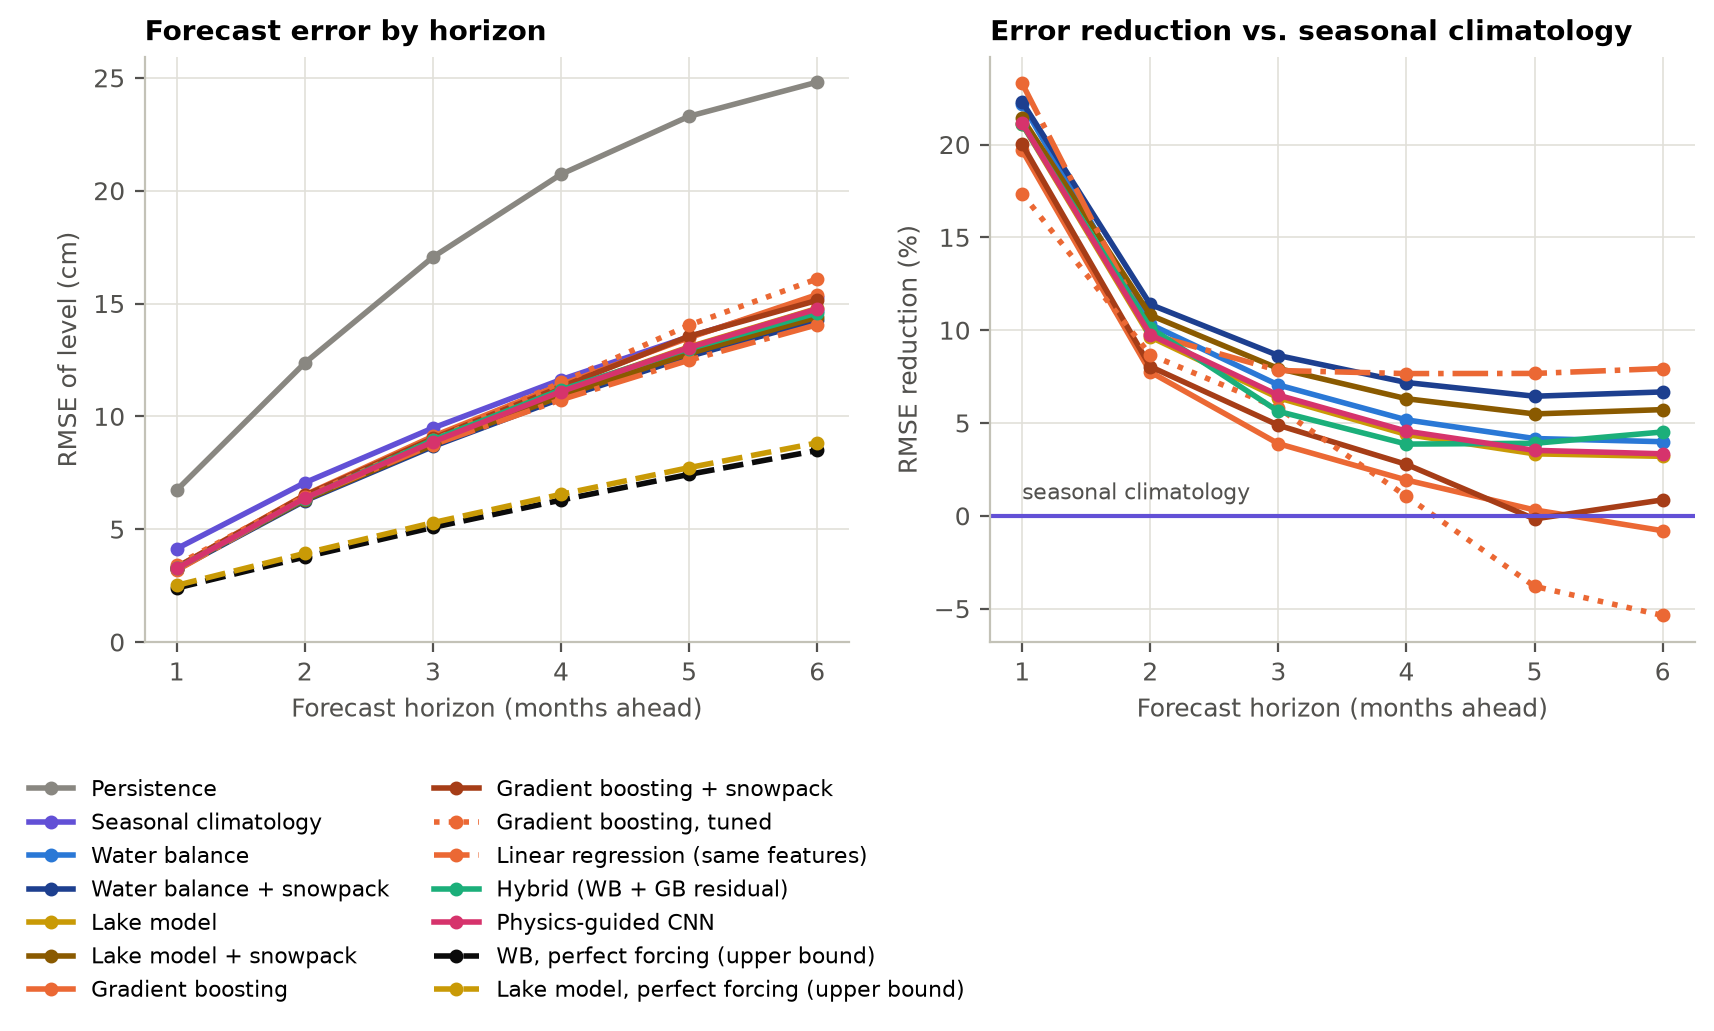

In [25]:
fig3_rmse(preds)
display(Image(str(FIGURES / "fig3_rmse_by_horizon.png"), width=800))

**Figure 4.** Which inputs the gradient-boosting model actually uses. Shuffle one
group of inputs and see how much the error grows; a big increase means the model
depended on it. Every test year is scored with the model the backtest trained before it, and the lines show 95% intervals. All
groups except the season are swapped between whole years, so they keep their seasonal cycle.

    horizon                      group  importance_cm  ci_low  ci_high
0         1             Season (month)           1.11    0.97     1.24
1         1              Current level           0.08    0.03     0.13
2         1        Recent level change           0.30    0.19     0.41
3         1              Precipitation           0.49    0.40     0.59
4         1                Evaporation           0.05   -0.01     0.11
5         1                     Runoff           0.51    0.37     0.66
6         1  Accumulated NBS (3-12 mo)          -0.01   -0.04     0.03
7         3             Season (month)           9.96    9.25    10.67
8         3              Current level           0.10   -0.23     0.40
9         3        Recent level change           0.51    0.29     0.73
10        3              Precipitation           0.33    0.16     0.50
11        3                Evaporation          -0.04   -0.19     0.09
12        3                     Runoff           0.21    0.00     0.41
13    

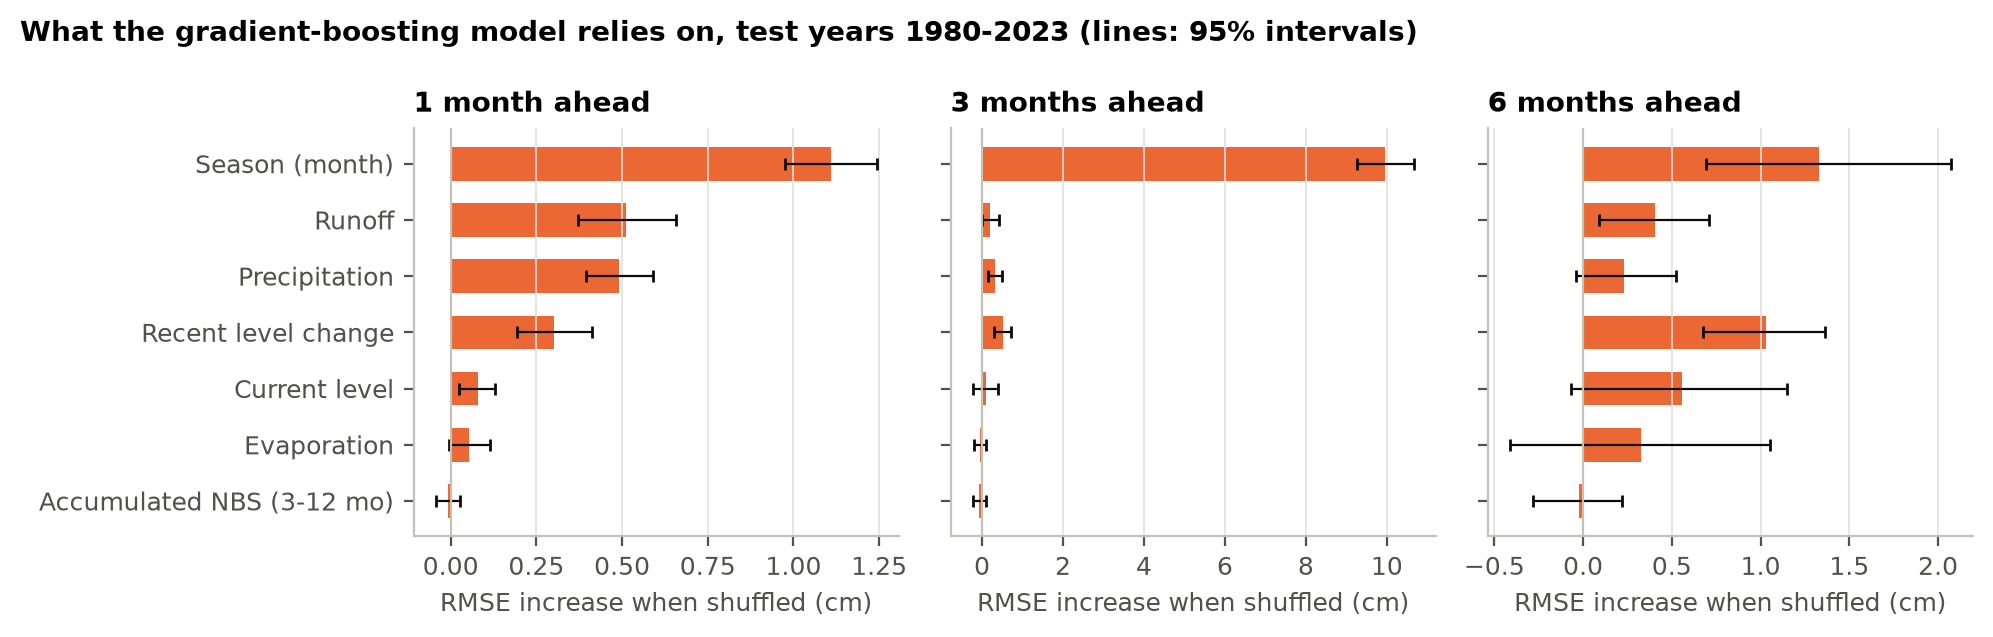

In [26]:
importance = permutation_importance(df)  # about 2 minutes
importance.to_csv(PROCESSED / "importance.csv", index=False, float_format="%.3f")
print(importance.round(2).to_string())
fig4_importance(importance)
display(Image(str(FIGURES / "fig4_feature_importance.png"), width=800))

**Figure 5.** The 2013 low to 2020 high: what the 6-month forecasts did, and which supply term drove the rise.

wrote figures/fig5_case_study_2013_2020.png
  case study: {'level_rise_m': 1.88, 'cum_precip_cm': 79.95, 'cum_minus_evap_cm': -59.49, 'cum_runoff_cm': 82.73}


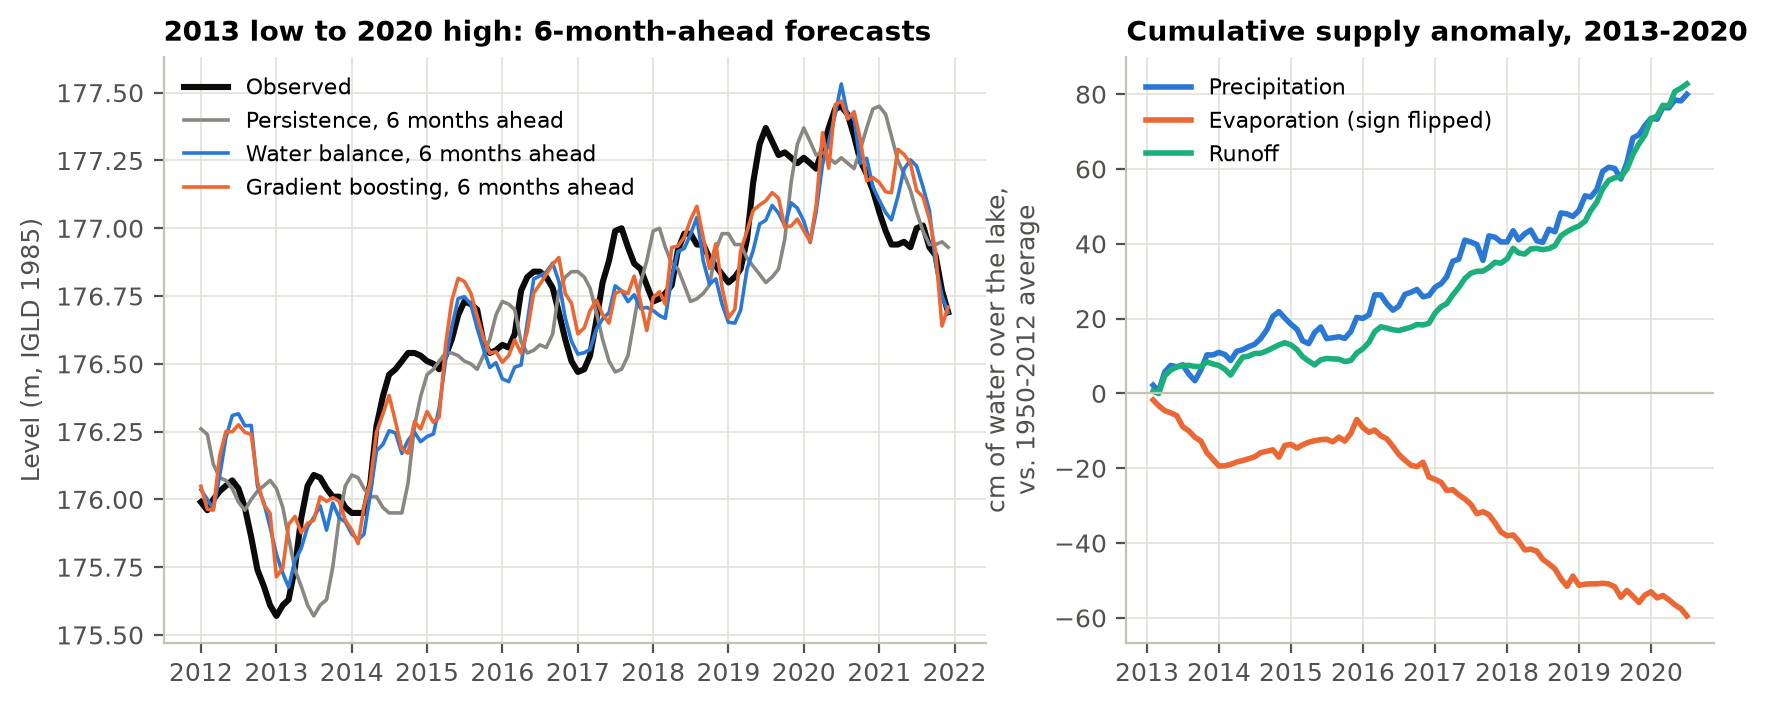

In [27]:
print("  case study:", {k: round(float(v), 2) for k, v in fig5_case_study(df, preds).items()})
display(Image(str(FIGURES / "fig5_case_study_2013_2020.png"), width=800))

**Figure 6.** The physics-guided CNN and how it is coupled to the lake model, drawn from a network trained on 1950-1979.

wrote figures/fig6_cnn_architecture.png


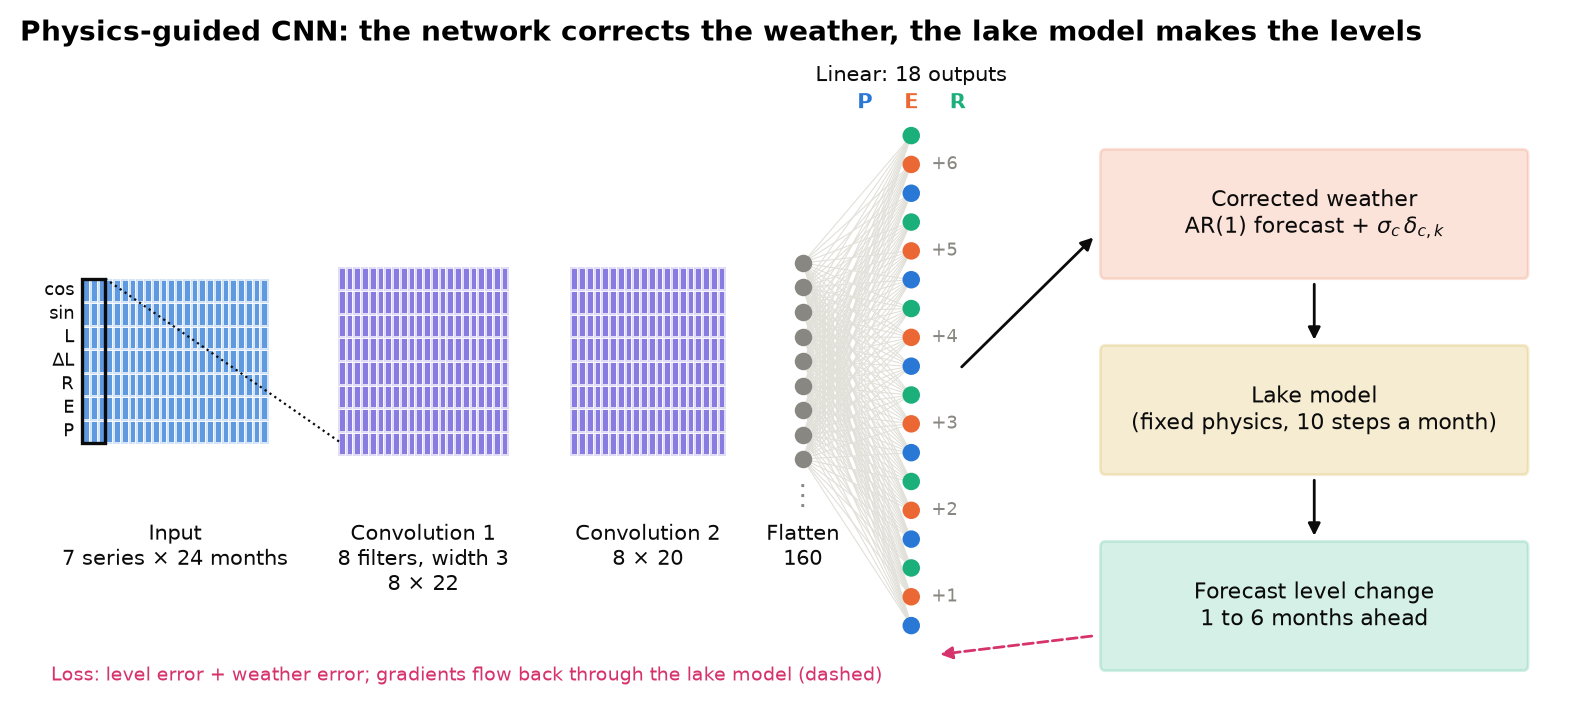

In [28]:
fig6_cnn(PhysicsCNN().fit(df.loc[:"1979-12"]))
display(Image(str(FIGURES / "fig6_cnn_architecture.png"), width=800))

## 8. Numbers quoted in the report

The water-balance coefficients fitted on the full record (saved to
`data/processed/wb_coefficients.csv`), and the RMSE table restricted to the
2013–2020 case-study years.

In [29]:
wb.coefficients().to_csv(PROCESSED / "wb_coefficients.csv", header=["coef"], float_format="%.4f")
print(wb.coefficients().round(3).to_string())
print("  AR(1) of P/E/R anomalies:", dict(zip(COMPONENTS, wb.phi_.round(2).tolist())))

month_1           -82.839
month_2           -78.546
month_3           -93.645
month_4           -78.085
month_5           -67.042
month_6           -74.861
month_7           -84.620
month_8          -110.054
month_9          -128.804
month_10         -135.559
month_11         -116.113
month_12          -89.627
precip_mm_lag0      0.354
evap_mm_lag0       -0.433
runoff_mm_lag0      1.224
precip_mm_lag1      0.531
evap_mm_lag1       -0.374
runoff_mm_lag1      0.607
level_m           -22.985
  AR(1) of P/E/R anomalies: {'precip_mm': 0.02, 'evap_mm': 0.26, 'runoff_mm': 0.45}


In [30]:
case = preds[(preds["target"] >= "2013-01") & (preds["target"] <= "2020-12")]
print("RMSE (cm), targets 2013-2020 only")
print(rmse_table(case).round(2).to_string())

RMSE (cm), targets 2013-2020 only
horizon                                       1      2      3      4      5      6
model                                                                             
Persistence                                7.00  12.94  17.88  21.84  24.75  26.65
Seasonal climatology                       4.04   6.99   9.41  11.76  14.01  16.14
Water balance                              2.89   5.96   8.33  10.54  12.86  15.02
Water balance + snowpack                   2.90   5.93   8.30  10.50  12.87  15.01
Lake model                                 2.91   5.97   8.34  10.56  12.90  15.07
Lake model + snowpack                      2.90   5.91   8.28  10.51  12.89  15.06
Gradient boosting                          3.04   6.18   8.39  10.63  12.69  14.64
Gradient boosting + snowpack               3.00   6.17   8.63  10.90  13.51  15.47
Gradient boosting, tuned                   3.08   6.15   8.49  11.01  13.80  15.89
Linear regression (same features)          2.81   6.0